<a href="https://colab.research.google.com/github/Riddhi1706/NEO_occulter/blob/main/looking_at_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install kete
import kete
import matplotlib.pyplot as plt
import numpy as np
%pip install astropy

import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')


import os
os.chdir('/content/drive/MyDrive/APEX')
df = pd.read_csv('atira_cleaned.csv')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 690.2/690.2 kB 5.0 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
earth_xyz = []

for jd in df["epoch_jd"].to_numpy():
    state = kete.spice.get_state("Earth", float(jd))

    earth_xyz.append([
        float(state.pos.x),
        float(state.pos.y),
        float(state.pos.z)
    ])

earth_xyz = np.array(earth_xyz, dtype=float)

print("NUMBER OF DATAFRAME ROWS:", len(df))
print("EARTH ARRAY SHAPE:", earth_xyz.shape)
print("EARTH ARRAY TYPE:", type(earth_xyz))
print("FIRST ROW:", earth_xyz[0])

NUMBER OF DATAFRAME ROWS: 38
EARTH ARRAY SHAPE: (38, 3)
EARTH ARRAY TYPE: <class 'numpy.ndarray'>
FIRST ROW: [-2.13964400e-01 -9.92221951e-01  5.97047370e-05]


In [3]:


def orbital_elements_to_xyz(a_au, e, i_deg, Omega_deg, omega_deg, M_deg):
    """
    Return heliocentric [x, y, z] position in AU.
    Position corresponds to the orbital elements at their epoch.
    """

    i = np.radians(i_deg)
    Omega = np.radians(Omega_deg)
    omega = np.radians(omega_deg)
    M = np.radians(M_deg)

    E = M

    for _ in range(50):
        delta = (E - e * np.sin(E) - M) / (1 - e * np.cos(E))
        E -= delta

        if abs(delta) < 1e-12:
            break

    # Position in orbital plane
    x_orb = a_au * (np.cos(E) - e)
    y_orb = a_au * np.sqrt(1 - e**2) * np.sin(E)

    # Rotate into heliocentric ecliptic coordinates
    x = (
        (np.cos(Omega) * np.cos(omega)
         - np.sin(Omega) * np.sin(omega) * np.cos(i)) * x_orb
        +
        (-np.cos(Omega) * np.sin(omega)
         - np.sin(Omega) * np.cos(omega) * np.cos(i)) * y_orb
    )

    y = (
        (np.sin(Omega) * np.cos(omega)
         + np.cos(Omega) * np.sin(omega) * np.cos(i)) * x_orb
        +
        (-np.sin(Omega) * np.sin(omega)
         + np.cos(Omega) * np.cos(omega) * np.cos(i)) * y_orb
    )

    z = (
        np.sin(omega) * np.sin(i) * x_orb
        +
        np.cos(omega) * np.sin(i) * y_orb
    )

    return np.array([x, y, z])



target_positions = np.array([
    orbital_elements_to_xyz(
        row["a_au"],
        row["e"],
        row["i_deg"],
        row["Omega_deg"],
        row["omega_deg"],
        row["M_deg"]
    )
    for _, row in df.iterrows()
])


observer_positions = np.array([
    [
        kete.spice.get_state("Earth", float(jd)).pos.x,
        kete.spice.get_state("Earth", float(jd)).pos.y,
        kete.spice.get_state("Earth", float(jd)).pos.z
    ]
    for jd in df["epoch_jd"]
])



df[["target_x_au", "target_y_au", "target_z_au"]] = target_positions

df[["observer_x_au", "observer_y_au", "observer_z_au"]] = observer_positions

# ============================================================
# Target - observer geometry
# ============================================================

target_observer_vectors = target_positions - observer_positions

df["target_observer_distance_au"] = np.linalg.norm(
    target_observer_vectors,
    axis=1
)

# Heliocentric target distance
df["target_sun_distance_au"] = np.linalg.norm(
    target_positions,
    axis=1
)

# Earth heliocentric distance
df["observer_sun_distance_au"] = np.linalg.norm(
    observer_positions,
    axis=1
)

print("Number of objects:", len(df))
print("Target positions:", target_positions.shape)
print("Observer positions:", observer_positions.shape)

print(
    df[
        [
            "name",
            "epoch_jd",
            "target_sun_distance_au",
            "observer_sun_distance_au",
            "target_observer_distance_au"
        ]
    ].head()
)


Number of objects: 38
Target positions: (38, 3)
Observer positions: (38, 3)
                       name   epoch_jd  target_sun_distance_au  \
0  163693 Atira (2003 CP20)  2461200.5                0.516636   
1       164294 (2004 XZ130)  2461200.5                0.719921   
2        413563 (2005 TG45)  2461200.5                0.871739   
3        418265 (2008 EA32)  2461200.5                0.777226   
4         434326 (2004 JG6)  2461200.5                0.666248   

   observer_sun_distance_au  target_observer_distance_au  
0                   1.01503                     0.963838  
1                   1.01503                     1.733546  
2                   1.01503                     0.607907  
3                   1.01503                     1.784572  
4                   1.01503                     1.303436  


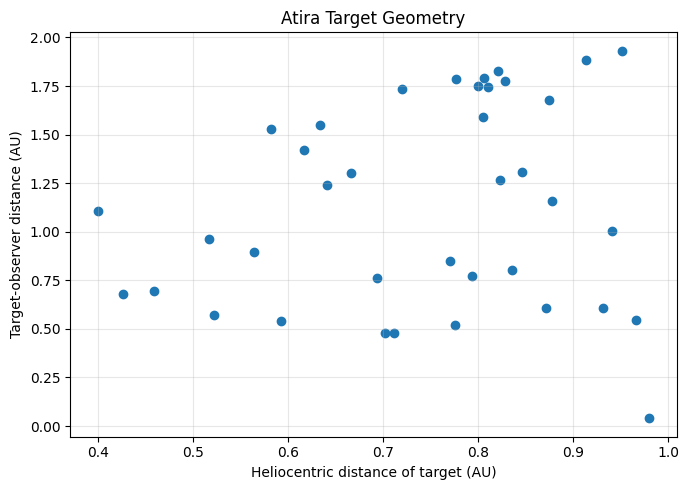

In [4]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df["target_sun_distance_au"],
    df["target_observer_distance_au"]
)

plt.xlabel("Heliocentric distance of target (AU)")
plt.ylabel("Target-observer distance (AU)")
plt.title("Atira Target Geometry")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# Target positions
target_positions = np.array([
    orbital_elements_to_xyz(
        row["a_au"],
        row["e"],
        row["i_deg"],
        row["Omega_deg"],
        row["omega_deg"],
        row["M_deg"]
    )
    for _, row in df.iterrows()
])

df["target_x_au"] = target_positions[:, 0]
df["target_y_au"] = target_positions[:, 1]
df["target_z_au"] = target_positions[:, 2]


# Observer positions
observer_positions = []

for jd in df["epoch_jd"]:
    state = kete.spice.get_state("Earth", float(jd))

    observer_positions.append([
        float(state.pos.x),
        float(state.pos.y),
        float(state.pos.z)
    ])

observer_positions = np.asarray(observer_positions, dtype=float)

df["observer_x_au"] = observer_positions[:, 0]
df["observer_y_au"] = observer_positions[:, 1]
df["observer_z_au"] = observer_positions[:, 2]


# Geometry
target_observer_vectors = target_positions - observer_positions

df["target_observer_distance_au"] = np.linalg.norm(
    target_observer_vectors,
    axis=1
)

df["target_sun_distance_au"] = np.linalg.norm(
    target_positions,
    axis=1
)

df["observer_sun_distance_au"] = np.linalg.norm(
    observer_positions,
    axis=1
)

In [6]:
target_observer_distances = np.linalg.norm(
    target_observer_vectors,
    axis=1
)

df["target_observer_distance_au"] = target_observer_distances

print("\nFirst 5 target-observer distances:")
print(df["target_observer_distance_au"].head())


First 5 target-observer distances:
0    0.963838
1    1.733546
2    0.607907
3    1.784572
4    1.303436
Name: target_observer_distance_au, dtype: float64


In [7]:
# Calculate target positions
target_positions = []

for _, row in df.iterrows():
    position = orbital_elements_to_xyz(
        row["a_au"],
        row["e"],
        row["i_deg"],
        row["Omega_deg"],
        row["omega_deg"],
        row["M_deg"]
    )

    target_positions.append(position)

target_positions = np.array(target_positions)


# Get Earth position for every asteroid epoch
observer_positions = []

for jd in df["epoch_jd"]:
    state = kete.spice.get_state("Earth", float(jd))

    observer_positions.append([
        float(state.pos.x),
        float(state.pos.y),
        float(state.pos.z)
    ])

# Convert explicitly to a 2D NumPy array
observer_positions = np.asarray(observer_positions, dtype=float)

# Check that everything has the same number of objects
print("Dataframe:", len(df))
print("Target positions:", len(target_positions))
print("Observer positions:", len(observer_positions))


# Add positions to dataframe
df[["target_x_au", "target_y_au", "target_z_au"]] = target_positions

df[["observer_x_au", "observer_y_au", "observer_z_au"]] = observer_positions

Dataframe: 38
Target positions: 38
Observer positions: 38


In [8]:
target_positions = df[
    ["target_x_au", "target_y_au", "target_z_au"]
].to_numpy()

observer_positions = df[
    ["observer_x_au", "observer_y_au", "observer_z_au"]
].to_numpy()

target_observer_vectors = target_positions - observer_positions

In [9]:
df["observer_distance_au"] = np.linalg.norm(
    target_observer_vectors,
    axis=1
)

In [10]:
observer_positions = []

for jd in df["epoch_jd"].to_numpy():

    earth = kete.spice.get_state("Earth", float(jd))

    observer_positions.append([
        earth.pos.x,
        earth.pos.y,
        earth.pos.z
    ])

observer_positions = np.array(observer_positions)

print("df shape:", df.shape)
print("observer_positions shape:", observer_positions.shape)

df shape: (38, 34)
observer_positions shape: (38, 3)


In [11]:
# import kete
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt

# # 1. Setup bands and wavelengths
# bands = kete.neos.BANDS
# band_wavelengths = list(bands)

# # 2. Extract diameters
# diameters = []
# for _, row in df.iterrows():
#     if "diameter" in row and pd.notna(row["diameter"]):
#         diameters.append(float(row["diameter"]))
#     elif "diameter_km" in row and pd.notna(row["diameter_km"]):
#         diameters.append(float(row["diameter_km"]))
#     else:
#         h_mag = float(row.get("H", 18.0))
#         albedo = float(row.get("albedo", 0.15))
#         diameters.append(kete.compute_diameter(h_mag, albedo))

# df["diameter_km"] = diameters

# # 3. Calculate NEATM Fluxes per asteroid
# all_thermal_fluxes = []
# all_total_fluxes = []

# for idx, row in df.iterrows():
#     target_pos = [row["target_x_au"], row["target_y_au"], row["target_z_au"]]
#     observer_pos = [row["observer_x_au"], row["observer_y_au"], row["observer_z_au"]]

#     vis_alb = float(row["albedo"]) if "albedo" in row and pd.notna(row["albedo"]) else 0.15
#     diam = float(row["diameter_km"])

#     out = kete.flux.neatm_model_flux(
#         target_pos,
#         observer_pos,
#         band_albedos=[vis_alb] * len(bands),
#         diameter=diam,
#         vis_albedo=vis_alb,
#         g_param=0.12,
#         band_wavelengths=band_wavelengths,
#     )

#     all_thermal_fluxes.append(out.thermal_fluxes)
#     all_total_fluxes.append(out.fluxes)

# thermal_fluxes = np.array(all_thermal_fluxes)
# total_fluxes = np.array(all_total_fluxes)

# with np.errstate(divide='ignore', invalid='ignore'):
#     ratio_thermal_total = np.where(total_fluxes > 0, thermal_fluxes / total_fluxes, 0)

# # 4. Plot Line Graph per Asteroid across Wavelength Bands
# plt.figure(figsize=(9, 6), dpi=150)

# # Loop through each asteroid row and plot its band spectrum as a line
# for idx, row in df.iterrows():
#     name = row.get("name", f"Asteroid {idx}")
#     plt.plot(
#         band_wavelengths,
#         ratio_thermal_total[idx, :],
#         marker='o',
#         linewidth=1.5,
#         alpha=0.7,
#         label=name if len(df) <= 10 else None  # Prevents overcrowded legend if many asteroids
#     )

# plt.xlabel("Band Wavelength (µm)", fontsize=11)
# plt.ylabel("Ratio (Thermal / Total Flux)", fontsize=11)
# plt.title("NEATM Thermal/Total Flux Band Spectra per Asteroid", fontsize=12)
# plt.grid(True, alpha=0.3)

# if len(df) <= 10:
#     plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# plt.tight_layout()
# plt.show()

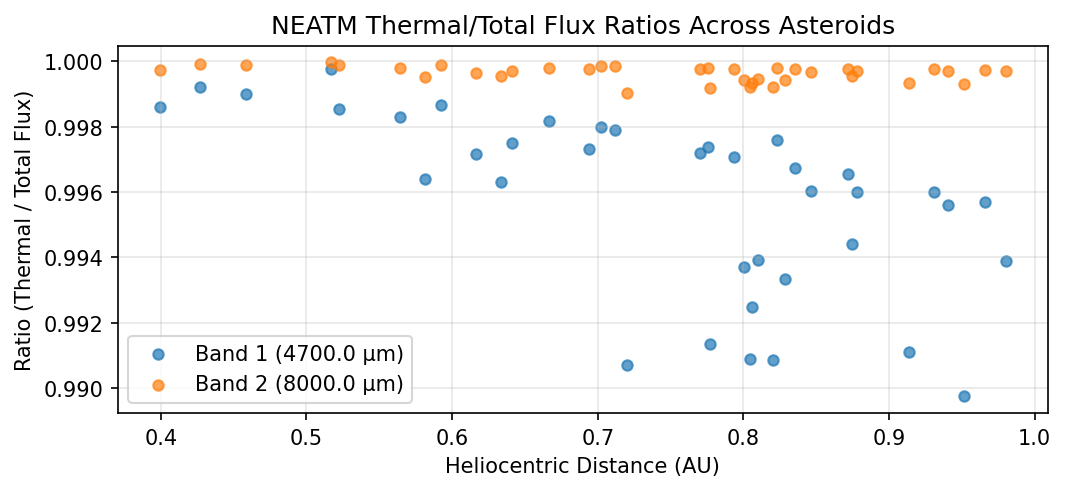

In [12]:
bands = kete.neos.BANDS
band_wavelengths = list(bands)

diameters = []
for _, row in df.iterrows():
    if "diameter" in row and pd.notna(row["diameter"]):
        diameters.append(float(row["diameter"]))
    elif "diameter_km" in row and pd.notna(row["diameter_km"]):
        diameters.append(float(row["diameter_km"]))


df["diameter_km"] = diameters

all_thermal_fluxes = []
all_total_fluxes = []

for idx, row in df.iterrows():
    target_pos = [row["target_x_au"], row["target_y_au"], row["target_z_au"]]
    observer_pos = [row["observer_x_au"], row["observer_y_au"], row["observer_z_au"]]

    vis_alb = float(row["albedo"]) if "albedo" in row and pd.notna(row["albedo"]) else 0.15
    diam = float(row["diameter_km"])

    out = kete.flux.neatm_model_flux(
        target_pos,
        observer_pos,
        band_albedos=[vis_alb] * len(bands),
        diameter=diam,
        vis_albedo=vis_alb,
        g_param=0.12,
        band_wavelengths=band_wavelengths,
    )

    all_thermal_fluxes.append(out.thermal_fluxes)
    all_total_fluxes.append(out.fluxes)

thermal_fluxes = np.array(all_thermal_fluxes)
total_fluxes = np.array(all_total_fluxes)

with np.errstate(divide='ignore', invalid='ignore'):
    ratio_thermal_total = np.where(total_fluxes > 0, thermal_fluxes / total_fluxes, 0)
    band_ratio = np.where(total_fluxes[:, 0] > 0, total_fluxes[:, 1] / total_fluxes[:, 0], 0)

plt.figure(figsize=(8, 7), dpi=150)

plt.subplot(2, 1, 1)
for band_idx, band_wl in enumerate(band_wavelengths):
    plt.scatter(
        df["target_sun_distance_au"],
        ratio_thermal_total[:, band_idx],
        label=f"Band {band_idx + 1} ({band_wl:.1f} µm)",
        alpha=0.7,
        s=25
    )

plt.ylabel("Ratio (Thermal / Total Flux)")
plt.xlabel("Heliocentric Distance (AU)")
plt.title("NEATM Thermal/Total Flux Ratios Across Asteroids")
plt.legend()
plt.grid(True, alpha=0.3)


In [13]:
np.random.seed(42)
#for data, need a new atira data, estimated any other data


# True physical parameters
# km
true_diam = df['diameter_km']
# geometric albedo
true_vis_albedo =df['albedo']
# NEATM beaming parameter
true_beaming = 1.2
# HG phase parameter
true_g_param = 0.15
# thermal emissivity (fixed, not fitted)
true_emissivity = 0.9
# IR-to-visible albedo ratio
true_r_ir = 1.6

# Derive H magnitude from diameter and albedo
true_h_mag = kete.compute_h_mag(true_diam, true_vis_albedo)

In [14]:
# Main-belt orbit
epoch = kete.Time.from_ymd(2024, 3, 15)
elements = kete.CometElements(
    desig="TestAsteroid",
    epoch=epoch,
    eccentricity=0.08,
    inclination=10.0,
    peri_arg=75.0,
    lon_of_ascending=45.0,
    peri_time=kete.Time(epoch.jd - 200),
    peri_dist=2.5,
)
state = elements.state
print(f"Orbit: a={elements.semi_major:.3f} AU, "
      f"e={elements.eccentricity:.3f}, "
      f"i={elements.inclination:.1f} deg")

Orbit: a=2.717 AU, e=0.080, i=10.0 deg


In [15]:
obs_jds = epoch.jd + np.array([0, 1, 5, 6, 14, 15, 29, 30])
print(f"Observing over {obs_jds[-1] - obs_jds[0]:.0f} day arc")

geometries = []
for jd in obs_jds:
    obj_state = kete.propagate_two_body(state, jd)
    earth = kete.spice.get_state("Earth", jd)
    sun2obj = obj_state.pos
    sun2obs = earth.pos
    geometries.append((sun2obj, sun2obs))

# Print example geometry
sun2obj_0, sun2obs_0 = geometries[0]
helio_dist = sun2obj_0.r
geo_dist = (sun2obj_0 - sun2obs_0).r
print(f"First epoch:  r_helio={helio_dist:.3f} AU, "
      f"r_geo={geo_dist:.3f} AU")

Observing over 30 day arc
First epoch:  r_helio=2.570 AU, r_geo=1.594 AU


In [16]:
import kete
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Load Data
# ============================================================
df = pd.read_csv('atira_cleaned.csv')

# Handle column naming variations
if 'albedo' in df.columns and 'vis_albedo' not in df.columns:
    df['vis_albedo'] = df['albedo']

# ============================================================
# 2. Compute Target and Observer Positions
# ============================================================
# Convert orbital elements -> heliocentric Cartesian position [x, y, z]
def orbital_elements_to_xyz(a_au, e, i_deg, Omega_deg, omega_deg, M_deg):
    i = np.radians(i_deg)
    Omega = np.radians(Omega_deg)
    omega = np.radians(omega_deg)
    M = np.radians(M_deg)

    # Solve Kepler's equation: M = E - e sin(E)
    E = M
    for _ in range(50):
        delta = (E - e * np.sin(E) - M) / (1 - e * np.cos(E))
        E -= delta
        if abs(delta) < 1e-12:
            break

    x_orb = a_au * (np.cos(E) - e)
    y_orb = a_au * np.sqrt(1 - e**2) * np.sin(E)

    x = (np.cos(Omega) * np.cos(omega) - np.sin(Omega) * np.sin(omega) * np.cos(i)) * x_orb + \
        (-np.cos(Omega) * np.sin(omega) - np.sin(Omega) * np.cos(omega) * np.cos(i)) * y_orb
    y = (np.sin(Omega) * np.cos(omega) + np.cos(Omega) * np.sin(omega) * np.cos(i)) * x_orb + \
        (-np.sin(Omega) * np.sin(omega) + np.cos(Omega) * np.cos(omega) * np.cos(i)) * y_orb
    z = np.sin(omega) * np.sin(i) * x_orb + np.cos(omega) * np.sin(i) * y_orb

    return [x, y, z]

target_positions = np.array([
    orbital_elements_to_xyz(
        row["a_au"], row["e"], row["i_deg"],
        row["Omega_deg"], row["omega_deg"], row["M_deg"]
    ) for _, row in df.iterrows()
])

observer_positions = np.array([
    [
        float(kete.spice.get_state("Earth", float(jd)).pos.x),
        float(kete.spice.get_state("Earth", float(jd)).pos.y),
        float(kete.spice.get_state("Earth", float(jd)).pos.z)
    ] for jd in df["epoch_jd"]
])

# ============================================================
# 3. NEATM Thermal Model Simulation Loop
# ============================================================
band_names = ["W1", "W2", "W3", "W4"]
true_r_ir = 1.6  # IR-to-visible albedo ratio
model_outputs = []

for idx, row in df.iterrows():
    # 1. Geometry vectors as Python lists [x, y, z]
    sun2obj = target_positions[idx].tolist()
    sun2obs = observer_positions[idx].tolist()

    # 2. Extract or fallback physical properties
    vis_albedo = float(row["vis_albedo"]) if "vis_albedo" in row and pd.notna(row["vis_albedo"]) else 0.15
    ir_albedo = vis_albedo * true_r_ir

    h_val = float(row["H"]) if "H" in row and pd.notna(row["H"]) else 18.0

    if "diameter" in row and pd.notna(row["diameter"]):
        diam_val = float(row["diameter"])
    else:
        # Compute diameter in km from H and albedo
        diam_val = float(kete.compute_diameter(h_val, vis_albedo))
        h_val = float(kete.compute_h_mag(diam_val, vis_albedo))
    # 3. Run NEATM model
    out = kete.flux.neatm_model_flux(
        sun2obj,
        sun2obs,
        band_albedos=[ir_albedo] * 4,
        h_mag=h_val,
        vis_albedo=vis_albedo,
        diameter=diam_val,
        beaming=1.2,
        g_param=0.15,
        emissivity=0.9,
        bands="wise"
    )
    model_outputs.append(out)

print(f"Successfully evaluated NEATM model for {len(model_outputs)} objects!")

# ============================================================
# 4. Extract Fluxes and View Results
# ============================================================
true_fluxes = {}
for idx, name in enumerate(band_names):
    true_fluxes[name] = [out.fluxes[idx] for out in model_outputs]

for name in band_names:
    flux_vals = [f"{f:.4f}" for f in true_fluxes[name][:5]]
    print(f"True {name} fluxes (Jy) [first 5 objects]: {flux_vals}")

Successfully evaluated NEATM model for 38 objects!
True W1 fluxes (Jy) [first 5 objects]: ['227.2113', '35.5003', '30.6020', '28.2358', '63.0738']
True W2 fluxes (Jy) [first 5 objects]: ['874.8788', '164.6425', '214.5785', '143.5374', '305.3830']
True W3 fluxes (Jy) [first 5 objects]: ['2760.0439', '826.0542', '2069.9086', '846.2987', '1384.1098']
True W4 fluxes (Jy) [first 5 objects]: ['2041.9164', '688.6819', '2224.4219', '742.9659', '1132.9713']


In [17]:
# if 'albedo' in df.columns:
#     df['vis_albedo'] = df['albedo']

# true_r_ir = 1.6  # IR-to-visible albedo ratio

# model_outputs = []

# # 2. Iterate through objects and use each row's visual albedo
# for idx, row in df.iterrows():
#     sun2obj = target_positions[idx]
#     sun2obs = observer_positions[idx]

#     # Extract object-specific physical values from the dataset
#     vis_albedo = float(row["vis_albedo"]) if pd.notna(row.get("vis_albedo")) else 0.15
#     ir_albedo = vis_albedo * true_r_ir

#     # Extract H magnitude or estimate from dataset columns
#     h_val = float(row["H"]) if "H" in row else float(row["h_mag"])

#     # Extract or compute diameter (km)
#     if "diameter" in row and pd.notna(row["diameter"]):
#         diam_val = float(row["diameter"])
#     elif "diameter_km" in row and pd.notna(row["diameter_km"]):
#         diam_val = float(row["diameter_km"])
#     else:
#         # Compute diameter from H-magnitude and dataset's vis_albedo
#         diam_val = float(kete.compute_diameter(h_val, vis_albedo))

#     # Evaluate NEATM thermal model with dataset values
#     out = kete.flux.neatm_model_flux(
#     sun2obj.tolist(),  # Convert NumPy array to Python list [x, y, z]
#     sun2obs.tolist(),  # Convert NumPy array to Python list [x, y, z]
#     band_albedos=[ir_albedo] * 4,
#     h_mag=h_val,
#     vis_albedo=vis_albedo,
#     diameter=diam_val,
#     beaming=1.2,
#     g_param=0.15,
#     emissivity=0.9,
#     bands="wise"
#     )

# model_outputs.append(out)
# # Extract true fluxes for all four bands
# true_fluxes = {}
# for idx, name in enumerate(band_names):
#     true_fluxes[name] = [out.fluxes[idx] for out in model_outputs]

# for name in band_names:
#     print(f"True {name} fluxes (Jy): "
#           f"{[f'{f:.4f}' for f in true_fluxes[name]]}")

In [18]:
# 5% flux uncertainty
sigma_frac = 0.05
observations = []

for i, (sun2obj, sun2obs) in enumerate(geometries):
    for name in band_names:
        true_flux = true_fluxes[name][i]
        sigma = sigma_frac * true_flux
        noisy_flux = true_flux + np.random.normal(0, sigma)
        obs = kete.flux.FluxObs(
            flux=noisy_flux,
            sigma=sigma,
            band=name,
            sun2obj=sun2obj,
            sun2obs=sun2obs,
        )
        observations.append(obs)

n_bands = len(band_names)
print(f"Created {len(observations)} FluxObs "
      f"({len(observations) // n_bands} epochs x {n_bands} bands)")

Created 32 FluxObs (8 epochs x 4 bands)


In [19]:
true_h_mag = float(df["H"].iloc[0]) if "H" in df.columns else 18.0
true_g_param = 0.15
true_emissivity = 0.9

observations = []

for idx, out in enumerate(model_outputs):
    sun2obj = target_positions[idx].tolist()
    sun2obs = observer_positions[idx].tolist()

    for band_idx, band in enumerate(band_names):
        true_flux = out.fluxes[band_idx]

        # Add 5% observational noise
        unc = max(0.05 * true_flux, 1e-6)

        # Wrap as kete.flux.FluxObs using 'sig' for uncertainty
        obs = kete.flux.FluxObs(
            sun2obj=sun2obj,
            sun2obs=sun2obs,
            band=band,
            flux=true_flux,
            sigma =unc
        )
        observations.append(obs)

result = kete.flux.fit_model(
    model="neatm",
    obs=observations,
    h_mag=true_h_mag,
    g_param=true_g_param,
    emissivity=true_emissivity,
    num_chains=4,
    num_tune=200,
    num_draws=500
)

# print(f"MCMC complete: {len(result.draws)} draws, "
#       f"{result.n_divergent} divergent")
# print(f"reduced chi2 = {result.chi2_best:.2f} "
#       f"(nobs = {result.nobs}, dof = {result.nobs - 6})")
# print(f"\nPosterior summary:")
# print(f"  Diameter:  {result.diameter}")
# print(f"  Albedo:    {result.vis_albedo}")
# print(f"  Beaming:   {result.beaming}")
# print(f"  H mag:     {result.h_mag}")
# print(f"  G param:   {result.g_param}")
# print(f"  R_IR:      {result.ir_albedo_ratio}")

TypeError: 'float' object is not subscriptable

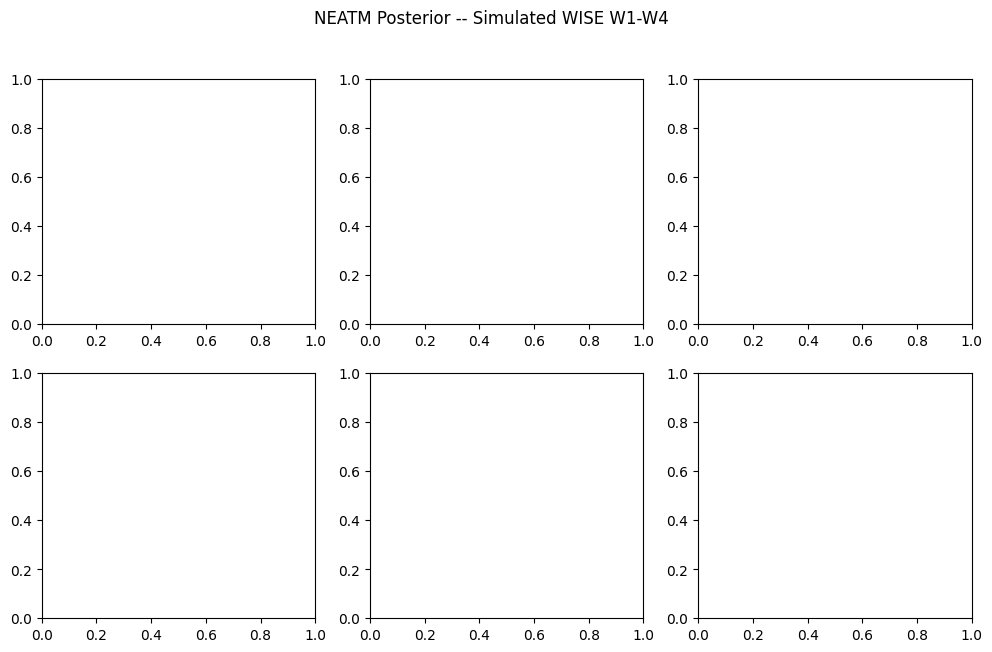

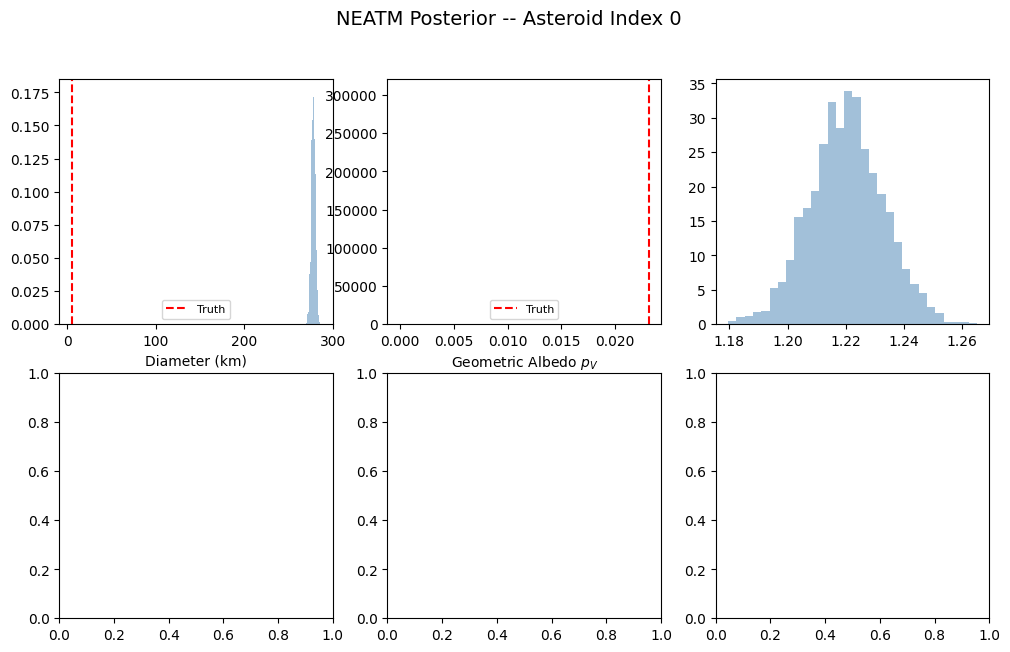

In [20]:
draws = np.array(result.draws)
columns = result.columns
true_vals = {
    "diameter": true_diam,
    "vis_albedo": true_vis_albedo,
    "beaming": true_beaming,
    "h_mag": true_h_mag,
    "g_param": true_g_param,
    "ir_albedo_ratio": true_r_ir,
}
labels = {
    "diameter": "Diameter (km)",
    "vis_albedo": r"Geometric Albedo $p_V$",
    "beaming": "Beaming",
    "h_mag": "H magnitude",
    "g_param": "G parameter",
    "ir_albedo_ratio": r"$R_{IR}$",
}
num_asteroids = len(true_vals["diameter"])
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
fig.suptitle("NEATM Posterior -- Simulated WISE W1-W4")

for ast_idx in range(num_asteroids):
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))
    fig.suptitle(f"NEATM Posterior -- Asteroid Index {ast_idx}", fontsize=14)

    for ax, col_name in zip(axes.flat, labels):
        idx = columns.index(col_name)
        vals = draws[:, idx]  # MCMC draws for this parameter

        # Plot histogram of posterior draws
        ax.hist(vals, bins=30, density=True, alpha=0.5, color="steelblue")

        true_val = true_vals[col_name][ast_idx]
        ax.axvline(true_val, color="red", ls="--", lw=1.5, label="Truth")

        ax.set_xlabel(labels[col_name])
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

In [ ]:
d_idx = columns.index("diameter")
pv_idx = columns.index("vis_albedo")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(draws[:, d_idx], draws[:, pv_idx],
           s=2, alpha=0.3, color="steelblue")
ax.scatter(true_diam, true_vis_albedo,
           c="red", s=80, marker="*", zorder=5, label="Truth")
ax.set_xlabel("Diameter (km)")
ax.set_ylabel(r"Geometric Albedo $p_V$")
ax.set_title(r"Diameter vs. Albedo ($D^2 \cdot p_V$ degeneracy)")
ax.legend()
plt.tight_layout()


In [ ]:
residuals = np.array(result.best_fit_residuals)
fit_fluxes = np.array(result.best_fit_fluxes)
obs_fluxes = np.array([o.flux for o in observations])

# Group observation indices by band
band_idx = {name: list(range(k, len(observations), n_bands))
            for k, name in enumerate(band_names)}
markers = {"W1": "D", "W2": "^", "W3": "o", "W4": "s"}
colors = {"W1": "C0", "W2": "C1", "W3": "C2", "W4": "C3"}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
for name in band_names:
    idx = band_idx[name]
    ax.errorbar(range(len(idx)), obs_fluxes[idx],
                yerr=[observations[i].sigma for i in idx],
                fmt=markers[name], ms=4, label=f"{name} obs",
                color=colors[name])
    ax.plot(range(len(idx)), fit_fluxes[idx], "x",
            ms=6, color=colors[name], label=f"{name} model")
ax.set_xlabel("Epoch index")
ax.set_ylabel("Flux (Jy)")
ax.set_title("Observed vs. MAP Model Fluxes")
ax.legend(fontsize=7, ncol=2)

ax = axes[1]
ax.bar(range(len(residuals)), residuals, color="steelblue", alpha=0.6)
ax.axhline(0, color="black", lw=0.5)
ax.axhline(1, color="gray", ls="--", lw=0.5)
ax.axhline(-1, color="gray", ls="--", lw=0.5)
ax.set_xlabel("Observation index")
ax.set_ylabel("Normalized residual")
ax.set_title(f"MAP Residuals ($\\chi^2_\\nu$ = {result.chi2_best:.2f}, "
             f"nobs = {result.nobs})")
plt.tight_layout()


In [ ]:
custom_priors = kete.flux.FluxPriors(
    beaming=kete.flux.ParamPrior(
        bounds=(0.5, 3.0),
        # tighter sigma
        gaussian=(1.0, 0.1),
    ),
)
result_custom = kete.flux.fit_model(
    model="neatm",
    obs=observations,
    h_mag=true_h_mag,
    g_param=true_g_param,
    priors=custom_priors,
    num_chains=4,
    num_tune=200,
    num_draws=500,
)
print(f"Default beaming: {result.beaming}")
print(f"Custom  beaming: {result_custom.beaming}")

In [ ]:
result_frm = kete.flux.fit_model(
    model="frm",
    obs=observations,
    h_mag=true_h_mag,
    g_param=true_g_param,
    emissivity=true_emissivity,
    num_chains=4,
    num_tune=200,
    num_draws=500,
)

print("FRM posterior summary:")
print(f"  Diameter:  {result_frm.diameter}")
print(f"  Albedo:    {result_frm.vis_albedo}")
print(f"  H mag:     {result_frm.h_mag}")
print(f"  R_IR:      {result_frm.ir_albedo_ratio}")
print(f"  reduced chi2: {result_frm.chi2_best:.2f} "
      f"(nobs = {result_frm.nobs}, dof = {result_frm.nobs - 5})")
print(f"\nNEATM reduced chi2: {result.chi2_best:.2f}")
print(f"FRM  reduced chi2:  {result_frm.chi2_best:.2f}")

In [ ]:
draws_frm = np.array(result_frm.draws)
columns_frm = result_frm.columns

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col_name, label, true_val in [
    (axes[0], "diameter", "Diameter (km)", true_diam),
    (axes[1], "vis_albedo", r"Geometric Albedo $p_V$", true_vis_albedo),
]:
    neatm_vals = draws[:, columns.index(col_name)]
    frm_vals = draws_frm[:, columns_frm.index(col_name)]
    ax.hist(neatm_vals, bins=30, density=True, alpha=0.5,
            color="steelblue", label="NEATM")
    ax.hist(frm_vals, bins=30, density=True, alpha=0.5,
            color="darkorange", label="FRM")
    ax.axvline(true_val, color="red", ls="--", lw=1.5, label="Truth")
    ax.set_xlabel(label)
    ax.legend(fontsize=8)

fig.suptitle("NEATM vs. FRM Posterior Comparison")
plt.tight_layout()

In [ ]:
residuals_frm = np.array(result_frm.best_fit_residuals)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

ax = axes[0]
ax.bar(range(len(residuals)), residuals, color="steelblue", alpha=0.6)
ax.axhline(0, color="black", lw=0.5)
ax.axhline(1, color="gray", ls="--", lw=0.5)
ax.axhline(-1, color="gray", ls="--", lw=0.5)
ax.set_xlabel("Observation index")
ax.set_ylabel("Normalized residual")
ax.set_title(f"NEATM ($\\chi^2_\\nu$ = {result.chi2_best:.2f})")

ax = axes[1]
ax.bar(range(len(residuals_frm)), residuals_frm, color="darkorange", alpha=0.6)
ax.axhline(0, color="black", lw=0.5)
ax.axhline(1, color="gray", ls="--", lw=0.5)
ax.axhline(-1, color="gray", ls="--", lw=0.5)
ax.set_xlabel("Observation index")
ax.set_title(f"FRM ($\\chi^2_\\nu$ = {result_frm.chi2_best:.2f})")

fig.suptitle("Residual Comparison: NEATM vs. FRM")
plt.tight_layout()